[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L5/BA_L5_portfolios/BA_L5_portfolios.ipynb)

# BA_L5_portfolios: Covariance beats penalties

*Quantlet of Lecture 5, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Annualised volatility and 5% expected shortfall of three long-only stablecoin portfolios (equal weight, global minimum variance, linear lambda from the De-pegging Pressure Index penalties), rebalanced weekly, 30 June 2020 - 31 May 2026 (EODHD data), against the values reported by Fan, Sha, Härdle & Pele (2026).

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

## Four long-only rules: covariance beats penalties

An investor holds reference-adjusted stablecoin positions (a treasury, a market maker, a lending desk), 30 June 2020 – 31 May 2026 (the paper's sample period).

**The rules** (rebalanced every 7 days with information up to day $t-1$, every weight capped at 30%):

- equal weight: $w_i = 1/J$;
- global minimum variance (GMV): $\min_w w'\hat\Sigma w$ subject to $\sum_i w_i = 1$, $0 \leq w_i \leq 0.3$, with $\hat\Sigma = 0.9\,S + 0.1\,\mathrm{diag}(S)$ and $S$ the sample covariance matrix of the last 90 days;
- linear lambda: $\min_w \sum_i w_i \hat\lambda_{i,t-1}$ under the same constraints, i.e. fill the coins with the lowest selected penalty first.

Between rebalancings the weights drift with the daily simple returns $R_{i,t} = e^{r_{i,t}/10^4} - 1$, where $r_{i,t}$ is the reference-adjusted log return in basis points (bp); the portfolio return is $\sum_i w_{i,t} R_{i,t}$.
Turnover is $\frac12 \sum_i |w_i^{target} - w_i^{drifted}|$ at each rebalancing; no transaction costs.
Outcomes: annualised return and volatility, the 5% expected shortfall (ES, the mean loss on the worst 5% of days, in bp), the maximum drawdown (max DD) and the turnover per rebalance.

The paper's fourth rule (quadratic lambda: penalty level plus covariance) is not replicated.

**Penalties.** The linear-lambda rule needs $\hat\lambda_{i,t-1}$ only on the days before the rebalancings, so the Quantile Lasso is estimated on these 342 days (every 7th day), the same values the lecture's daily run gives on these days.

**The De-pegging Pressure Index (DPI).** For each coin $j$ and day $t$, a 5% Quantile Lasso on the 90 days before $t$: the target is $d_{j,s}$; the predictors are the other coins' $d_{k,s}$ (same day) and the one-day-lagged changes of the US dollar index (DXY), the CBOE volatility index (VIX), the S&P 500 index (log changes) and the 1-year Treasury yield (first differences).
Every variable is centred by its window median and divided by $1.4826 \times$ its median absolute deviation (MAD). With the check loss $\rho_\tau(e) = e\,(\tau - \mathbb 1\{e < 0\})$,
$$ (\hat\alpha, \hat\beta)(\lambda) = \arg\min_{\alpha, \beta} \sum_{s \in W_t} \rho_{0.05}\big(d_{j,s} - \alpha - \mathbf x_{j,s}'\beta\big) + \lambda \sum_k |\beta_k| , $$
and $\hat\lambda_{j,t}$ minimises the generalised approximate cross-validation (GACV) criterion $\sum_s \rho_\tau(\hat e_s) / (n - \mathrm{df})$, $\mathrm{df} = \#\{\hat\beta_k \neq 0\} + 1$, over 25 values from $10^{-4}\lambda_{max}$ to $\lambda_{max}$. The index is the average selected penalty:
$$ \mathrm{DPI}_t = \frac{1}{J}\sum_{j=1}^{J} \hat\lambda_{j,t} . $$
The DPI is not a depeg probability; it is a model-implied measure of lower-tail dependence. Method of Fan, Sha, Härdle & Pele (2026); the penalty as a risk measure comes from the Financial Risk Meter (FRM) of [Mihoci, Althof, Chen & Härdle (2020)](https://doi.org/10.1108/S0731-905320200000042016).

**How to read the chart.** Left: annualised volatility; right: 5% ES of daily returns; blue: the paper (CoinGecko prices, 11 coins), orange: this replication on the same period.

In [4]:
# Data: 10 stablecoins, their reference assets and four market variables, 1 January 2020 - 23 October 2026
import matplotlib
plt.rcParams['font.size'] = 10
END, END_PAPER = '2026-10-23', '2026-05-31'          # last day of the lecture sample; last day of the paper's sample
COINS = ['USDT', 'USDC', 'DAI', 'TUSD', 'USDP', 'GUSD', 'BUSD', 'SUSD', 'PAXG', 'EURS']
cal = pd.date_range('2020-01-01', END)


def weekdays(x):
    """EUR/USD and gold: Monday-Friday closes, repeated closes removed (the weekend bars come from a thin session)."""
    x = x[x.index.dayofweek < 5]
    return x[x.diff() != 0]


def finish_fig(fig, name, bottom, ncol=3):
    """Legend below the plot, then save and show."""
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))
    save_fig(fig, name)


ref = {'EURS': weekdays(daily('EURUSD.FOREX', END)), 'PAXG': weekdays(daily('XAUUSD.FOREX', END))}
P = pd.DataFrame({c: daily(f'{c}-USD.CC', END) for c in COINS}).reindex(cal).ffill(limit=7)    # past-only fill, at most 7 days
lr = 1e4 * np.log(P).diff()
bad = (lr.abs() > 1000) & (-lr.shift(-1) / lr >= 0.9)      # bad print: a move beyond 1000 bp, reversed by >= 90% the next day
P_raw = P.copy()                                           # prices as recorded
P = P.mask(bad).ffill(limit=7)                             # retrospective cleaning
Bm = pd.DataFrame({c: (ref[c].reindex(cal).ffill() if c in ref else pd.Series(1.0, index=cal)) for c in COINS})
D = 1e4 * (P / Bm - 1)                                     # reference-adjusted deviation d (bp)
D_raw = 1e4 * (P_raw / Bm - 1)                             # same, prices as recorded
R = 1e4 * np.log(P / Bm).diff()                            # reference-adjusted log return (bp)
mac = pd.DataFrame({'DXY': daily('DXY.INDX', END), 'VIX': daily('VIX.INDX', END), 'SPX': daily('GSPC.INDX', END),
                    'US1Y': daily('US1Y.GBOND', END)}).reindex(cal).ffill()
M = pd.DataFrame({'DXY': np.log(mac['DXY']).diff(), 'VIX': np.log(mac['VIX']).diff(), 'SPX': np.log(mac['SPX']).diff(),
                  'US1Y': mac['US1Y'].diff()}).shift(1)     # market changes, lagged one day
print(f'calendar {cal[0].date()} to {cal[-1].date()} ({len(cal)} days); bad prints removed: {int(bad.values.sum())}')

calendar 2020-01-01 to 2026-10-23 (2488 days); bad prints removed: 9


In [5]:
# 5% Quantile Lasso, penalty chosen by GACV, one equation per coin and day
from scipy.optimize import linprog
from joblib import Parallel, delayed
TAU, WIN, NGRID, LO = 0.05, 90, 25, 1e-4      # quantile level, window (days), grid size, lowest penalty / lambda_max
N_JOBS = os.cpu_count() or 1


def rho(e, tau=TAU):
    """Check loss."""
    return e * (tau - (e < 0))


def qlasso(X, y, lam):
    """Quantile Lasso as a linear programme: y = a+ - a- + X(b+ - b-) + u - v, minimise lam |b| + tau u + (1 - tau) v."""
    n, p = X.shape
    c = np.concatenate([[0, 0], lam * np.ones(2 * p), TAU * np.ones(n), (1 - TAU) * np.ones(n)])
    A = np.hstack([np.ones((n, 1)), -np.ones((n, 1)), X, -X, np.eye(n), -np.eye(n)])
    z = linprog(c, A_eq=A, b_eq=y, bounds=[(0, None)] * len(c), method='highs').x
    return z[0] - z[1], z[2:2 + p] - z[2 + p:2 + 2 * p]


def robust(Z):
    """Centre by the median, divide by 1.4826 x MAD (by the sd if the MAD is zero); drop constant columns."""
    med = np.median(Z, axis=0)
    mad = 1.4826 * np.median(np.abs(Z - med), axis=0)
    s = np.where(mad > 0, mad, Z.std(axis=0))
    keep = s > 0
    return (Z[:, keep] - med[keep]) / s[keep], keep


def fit_eq(y, X, lo=LO):
    """GACV-selected penalty on 25 values in [lo, 1] x lambda_max: returns (lambda, GACV, slopes, grid position)."""
    n = len(y)
    if X.shape[1] == 0:
        return np.nan, rho(y - np.quantile(y, TAU)).sum() / (n - 1), np.array([]), -1
    lmax = np.abs(X.T @ (TAU - (y < np.quantile(y, TAU)))).max()
    best = None
    for k, lam in enumerate(np.geomspace(lmax * lo, lmax, NGRID)):
        a, b = qlasso(X, y, lam)
        df = 1 + (np.abs(b) > 1e-8).sum()
        g = rho(y - a - X @ b).sum() / (n - df)
        if best is None or g < best[1]:
            best = (lam, g, b, k)
    return best


def window(t_idx):
    """Deviations of the 90 days before day t as known on day t: cleaned, except the last day (not yet checkable)."""
    Dw = D.iloc[t_idx - WIN:t_idx].copy()
    Dw.iloc[-1] = D_raw.iloc[t_idx - 1]
    return Dw


def day(t_idx, blocks=('coin', 'macro'), lo=LO):
    """All coin equations of calendar row t_idx: target d_j, predictors the other coins' d and the lagged market changes."""
    Dw = window(t_idx)
    out = {}
    for c in COINS:
        y = Dw[c].values
        if np.isnan(y).any():
            continue
        y = (y - np.median(y)) / (1.4826 * np.median(np.abs(y - np.median(y))) or y.std() or 1)
        parts, names = [], []
        if 'coin' in blocks:
            Xc = Dw.drop(columns=c)
            ok = ~np.isnan(Xc.values).any(axis=0)
            parts.append(Xc.values[:, ok]); names += list(Xc.columns[ok])
        if 'macro' in blocks:
            parts.append(M.values[t_idx - WIN:t_idx]); names += list(M.columns)
        Zs, keep = robust(np.hstack(parts))
        names = [nm for nm, k in zip(names, keep) if k]
        lam, g, b, k = fit_eq(y, Zs, lo)
        out[c] = dict(lam=lam, gacv=g, k=k, coef=dict(zip(names, b)))
    return t_idx, out


def run_days(idx, lo=LO):
    """Estimate all equations on the calendar rows idx, in parallel on all processor cores."""
    chunks = [c for c in np.array_split(np.asarray(idx), 4 * N_JOBS) if len(c)]
    out = Parallel(n_jobs=N_JOBS)(delayed(lambda ix: [day(i, lo=lo) for i in ix])(c) for c in chunks)
    return {i: o for part in out for i, o in part}


first = cal.get_loc(pd.Timestamp('2020-04-01'))           # first DPI day: 90 days of history
weekly = [i for i in range(first, len(cal)) if (cal[i] - pd.Timestamp('2020-06-29')).days % 7 == 0]   # days before the rebalancings

import time
t0 = time.time()
LAM = pd.DataFrame({cal[i]: {c: v['lam'] for c, v in o.items()} for i, o in run_days(weekly).items()}).T[COINS].sort_index()
print(f'penalties on {len(LAM)} days estimated in {time.time() - t0:.0f} s')

penalties on 342 days estimated in 36 s


In [6]:
# Portfolio rules, rebalanced every 7 days with information up to t-1; weights capped at 30%
from scipy.optimize import minimize
RS = np.expm1(R / 1e4)                                                 # simple reference-adjusted return of day t
RS_rt = np.expm1((np.log(P_raw / Bm) - np.log(P / Bm).shift(1)))       # day-s return as seen at the end of day s


def gmv(hist, avail):
    """Global minimum variance, long only, cap 30%, covariance shrunk 10% towards its diagonal."""
    S = hist[avail].cov().values
    S = 0.9 * S + 0.1 * np.diag(np.diag(S))
    Sn = S / np.median(np.diag(S))                                     # rescale: variances differ by up to 1e6
    x0 = 1 / np.diag(Sn); x0 = np.minimum(x0 / x0.sum(), 0.3); x0 /= x0.sum()
    r_ = minimize(lambda w: w @ Sn @ w, x0, jac=lambda w: 2 * Sn @ w, bounds=[(0, 0.3)] * len(avail),
                  constraints=({'type': 'eq', 'fun': lambda w: w.sum() - 1},), method='SLSQP',
                  options={'ftol': 1e-12, 'maxiter': 500})
    w = np.clip(r_.x, 0, None)
    return pd.Series(w / w.sum(), index=avail)


def targets(t_, rules):
    """Target weights at the close of day t-1, from information up to t-1 (the last day as recorded)."""
    hist = RS.loc[:t_ - pd.Timedelta(days=1)].iloc[-90:].copy()
    hist.iloc[-1] = RS_rt.loc[t_ - pd.Timedelta(days=1)]
    avail = [c for c in COINS if hist[c].notna().all() and not np.isnan(P_raw[c].loc[t_ - pd.Timedelta(days=1)])]
    new = {'equal weight': pd.Series(1 / len(avail), index=avail), 'global minimum variance': gmv(hist, avail)}
    if 'linear lambda' in rules:                                       # fill the coins with the lowest penalty first
        lam_ = LAM.loc[:t_ - pd.Timedelta(days=1)].iloc[-1].reindex(avail).fillna(np.inf)
        wl = pd.Series(0.0, index=avail); left = 1.0
        for c in lam_.sort_values().index:
            wl[c] = min(0.3, left); left -= wl[c]
            if left <= 1e-12:
                break
        new['linear lambda'] = wl
    return {k: new[k].reindex(COINS).fillna(0.0) for k in rules}


def run(end, rules):
    """Holdings simulation from 30 June 2020: reset to the targets every 7 days, weights drift with prices in between."""
    days_ = R.loc['2020-06-30':end].index
    reb = set(days_[::7])
    held = {k: None for k in rules}
    W = {k: pd.DataFrame(0.0, index=days_, columns=COINS) for k in rules}
    rp = {k: pd.Series(0.0, index=days_) for k in rules}
    turn = {k: [] for k in rules}
    for t_ in days_:
        if t_ in reb:
            tg = TG[t_]
            for k in rules:
                if held[k] is not None:
                    turn[k].append(0.5 * (tg[k] - held[k]).abs().sum())
                held[k] = tg[k].copy()
        r_t = RS.loc[t_].reindex(COINS).fillna(0.0)
        for k in rules:
            W[k].loc[t_] = held[k]
            g = held[k] * (1 + r_t)
            rp[k].loc[t_] = g.sum() - 1
            held[k] = g / g.sum()                                      # drift
    out = {}
    for k in rules:
        v = 1e4 * rp[k].values                                         # bp a day
        nav = np.cumprod(1 + rp[k].values)
        out[k] = {'return (% a year)': v.mean() * 365 / 100, 'volatility (% a year)': v.std() * np.sqrt(365) / 100,
                  'ES 5% (bp a day)': -v[v <= np.quantile(v, 0.05)].mean(),
                  'max drawdown (%)': 100 * (1 - nav / np.maximum.accumulate(nav)).max(),
                  'turnover per rebalance (%)': 100 * np.mean(turn[k])}
    return pd.DataFrame(out).T, W, pd.DataFrame(rp)

RULES = ['equal weight', 'global minimum variance', 'linear lambda']
TG = {t_: targets(t_, RULES) for t_ in R.loc['2020-06-30':END_PAPER].index[::7]}
PT, Wp, _ = run(END_PAPER, RULES)

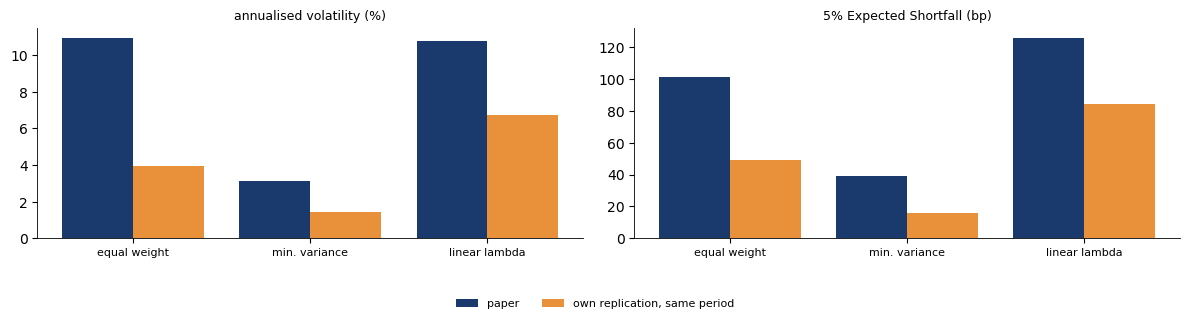

In [7]:
paper = pd.DataFrame({'paper: volatility (% a year)': [10.93, 3.14, 10.76], 'paper: ES 5% (bp a day)': [101.39, 39.03, 125.74],
                      'paper: max drawdown (%)': [15.6, 2.6, 16.5]}, index=RULES)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
xx = np.arange(3)
for j, (lab, col, pcol) in enumerate([('annualised volatility (%)', 'volatility (% a year)', 'paper: volatility (% a year)'),
                                      ('5% Expected Shortfall (bp)', 'ES 5% (bp a day)', 'paper: ES 5% (bp a day)')]):
    ax[j].bar(xx - 0.2, paper[pcol].values, width=0.4, color=BLUE, label=('paper' if j == 0 else None))
    ax[j].bar(xx + 0.2, PT[col].values, width=0.4, color=BTC, label=('own replication, same period' if j == 0 else None))
    ax[j].set_xticks(xx); ax[j].set_xticklabels(['equal weight', 'min. variance', 'linear lambda'], fontsize=8); ax[j].set_title(lab, fontsize=9)
finish_fig(fig, 'ba_l5_portfolios', 0.13, ncol=2)

In [8]:
ew_, gm_ = PT.loc['equal weight'], PT.loc['global minimum variance']
print('Portfolios, 30 June 2020 - 31 May 2026')
print(f"GMV against equal weight: volatility {100 * (1 - gm_['volatility (% a year)'] / ew_['volatility (% a year)']):.0f}% lower, "
      f"ES {100 * (1 - gm_['ES 5% (bp a day)'] / ew_['ES 5% (bp a day)']):.0f}% lower (paper: 71% and 62%)")
PT.join(paper).round(2)

Portfolios, 30 June 2020 - 31 May 2026
GMV against equal weight: volatility 63% lower, ES 67% lower (paper: 71% and 62%)


,return (% a year),volatility (% a year),ES 5% (bp a day),max drawdown (%),turnover per rebalance (%),paper: volatility (% a year),paper: ES 5% (bp a day),paper: max drawdown (%)
equal weight,-0.51,3.92,48.96,6.55,0.26,10.93,101.39,15.6
global minimum variance,0.05,1.43,15.93,1.71,3.68,3.14,39.03,2.6
linear lambda,-2.46,6.72,84.19,19.03,57.03,10.76,125.74,16.5


GMV cuts volatility and ES by about two thirds against equal weight, while penalty-based weights add risk and turnover: the selected penalty measures how the other coins move in a coin's lower tail, not the coin's own risk.